# Notebook 14 – EDA Mini Challenge

## Exploratory Data Analysis – Independent Analysis

This notebook demonstrates an independent Exploratory Data Analysis workflow.

The analysis covers:

1. Load the dataset
2. Understand the dataset
3. Inspect the structure
4. Identify data types
5. Identify missing values
6. Identify duplicates
7. Analyze numerical features
8. Analyze categorical features
9. Detect outliers
10. Analyze distributions
11. Analyze correlations
12. Create meaningful visualizations
13. Identify important patterns
14. Write business insights
15. Provide recommendations for the next preprocessing stage

## Question 1: How do we load the dataset?

### Step 1 – Understand the concept

The first step of EDA is to load the dataset into a Pandas DataFrame.

### Step 2 – Demonstrate the concept

The Telco Customer Churn dataset is stored as a CSV file.

### Step 3 – Implementation the concept

We use Pandas `read_csv()` to load the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


### Observation / Insight

The dataset was successfully loaded into a Pandas DataFrame.

The dataset contains **7043 records and 21 columns**.

## Question 2: What does the dataset contain?

### Step 1 – Understand the concept

Understanding the dataset helps identify the type of information available and the business context.

### Step 2 – Demonstrate the concept

This dataset contains customer information from the telecommunications domain.

It includes customer demographics, service information, contract details, charges, and churn information.

### Step 3 – Implementation the concept

We inspect the first few records and column names.

In [2]:
print("First 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


### Observation / Insight

The dataset contains customer-level information related to telecom services.

The target variable is **Churn**, which indicates whether a customer left the service.

## Question 3: What is the structure of the dataset?

### Step 1 – Understand the concept

Dataset structure includes the number of rows, columns, and the overall organization of the data.

### Step 2 – Demonstrate the  concept

Understanding the structure helps determine the scale of the dataset and the available features.

### Step 3 – Implementation the concept

We inspect the shape, information, and sample records.

In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nDataset Information:")
df.info()

Number of Rows: 7043
Number of Columns: 21

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 n

### Observation / Insight

The dataset contains **7043 rows and 21 columns**.

The dataset contains both numerical and categorical features, which require different types of analysis.

## Question 4: What are the data types of the features?

### Step 1 – Understand the concept

Data types determine how each feature should be analyzed and processed.

### Step 2 – Demonstrate the concept

Numerical features can be analyzed using statistical measures, while categorical features require frequency and category-based analysis.

### Step 3 – Implementation the concept

We inspect the data type of every column.

In [4]:
print("Data Types:")
print(df.dtypes)

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


### Observation / Insight

The dataset contains both numerical and categorical variables.

`TotalCharges` may appear as an object/string data type in the original dataset even though it represents numerical values.

This data-type issue should be corrected during the preprocessing stage.

## Question 5: Are there any missing values?

### Step 1 – Understand the concept

Missing values represent unavailable or blank information in the dataset.

### Step 2 – Demonstrate the concept

Missing values can affect statistical analysis and machine learning models.

### Step 3 – Implementation the concept

We calculate missing values and their percentages for every column.

In [5]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

print(missing_summary[missing_summary["Missing_Count"] > 0])

Empty DataFrame
Columns: [Missing_Count, Missing_Percentage]
Index: []


### Observation / Insight

The missing-value summary helps identify columns that require attention.

Blank or missing values should be investigated and an appropriate treatment should be selected during preprocessing.

## Question 6: Are there duplicate records?

### Step 1 – Understand the concept

Duplicate records are repeated rows that may affect analysis and model training.

### Step 2 – Demonstrate the concept

If duplicate customer records exist, they may cause certain observations to be overrepresented.

### Step 3 – Implementation the concept

We count duplicate rows in the dataset.

In [6]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


### Observation / Insight

The duplicate count indicates whether repeated records are present.

Any detected duplicates should be investigated before deciding whether they should be removed during preprocessing.

## Question 7: What can we learn from the numerical features?

### Step 1 – Understand the concept

Numerical features can be analyzed using measures such as mean, median, minimum, maximum, standard deviation, and quartiles.

### Step 2 – Demonstrate the concept

Important numerical features in this dataset include:

- tenure
- MonthlyCharges
- TotalCharges

### Step 3 – Implementation the concept

We calculate descriptive statistics for the numerical features.

In [7]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

numerical_data = df[numerical_features].copy()

numerical_data["TotalCharges"] = pd.to_numeric(
    numerical_data["TotalCharges"],
    errors="coerce"
)

print("Numerical Feature Statistics:")
display(numerical_data.describe())

Numerical Feature Statistics:


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


### Observation / Insight

The numerical summary shows differences in the center and spread of customer tenure and charges.

`TotalCharges` should be converted to a proper numerical data type during preprocessing.

## Question 8: What can we learn from the categorical features?

### Step 1 – Understand the concept

Categorical features contain groups or categories rather than continuous numerical values.

### Step 2 – Demonstrate the concept

Examples include:

- Contract
- InternetService
- PaymentMethod
- Partner
- Dependents
- Churn

### Step 3 – Implementation the concept

We examine the number of unique categories and their frequencies.

In [8]:
categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "Contract",
    "PaymentMethod",
    "InternetService",
    "Churn"
]

for column in categorical_features:
    print(f"\n--- {column} ---")
    print("Unique Values:", df[column].nunique())
    print(df[column].value_counts())


--- gender ---
Unique Values: 2
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- SeniorCitizen ---
Unique Values: 2
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

--- Partner ---
Unique Values: 2
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Unique Values: 2
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- Contract ---
Unique Values: 3
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

--- PaymentMethod ---
Unique Values: 4
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

--- InternetService ---
Unique Values: 3
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- Churn ---
Unique Values: 2
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### Observation / Insight

Categorical features contain different numbers of categories.

Contract, InternetService, and PaymentMethod show meaningful customer groupings that can be useful for further churn analysis.

## Question 9: Are there any potential outliers?

### Step 1 – Understand the concept

Outliers are observations that are unusually far from the typical values of a feature.

### Step 2 – Demonstrate the concept

The IQR method can be used to identify potential outliers in numerical features.

### Step 3 – Implementation the concept

We calculate the lower and upper bounds using the IQR method.

In [9]:
for column in numerical_features:
    data = pd.to_numeric(df[column], errors="coerce").dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    print(f"\n--- {column} ---")
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))
    print("Potential Outliers:", len(outliers))


--- tenure ---
Lower Bound: -60.0
Upper Bound: 124.0
Potential Outliers: 0

--- MonthlyCharges ---
Lower Bound: -46.02
Upper Bound: 171.38
Potential Outliers: 0

--- TotalCharges ---
Lower Bound: -4688.48
Upper Bound: 8884.67
Potential Outliers: 0


### Observation / Insight

Potential outliers are identified using the IQR method.

Outliers should not be removed automatically because extreme values may represent genuine customer behavior.

They should be investigated before deciding whether to retain, transform, or remove them.

## Question 10: What are the distributions of the numerical features?

### Step 1 – Understand the concept

Distribution analysis helps understand the shape, center, spread, and skewness of numerical variables.

### Step 2 – Demonstrate the concept

A histogram can show whether a feature is approximately symmetric, left-skewed, or right-skewed.

### Step 3 – Implementation the concept

We calculate skewness for the numerical features.

In [10]:
for column in numerical_features:
    data = pd.to_numeric(df[column], errors="coerce")

    skewness = data.skew()

    if skewness > 0.5:
        distribution = "Right-Skewed"
    elif skewness < -0.5:
        distribution = "Left-Skewed"
    else:
        distribution = "Approximately Symmetric"

    print(
        f"{column}: "
        f"Skewness = {skewness:.2f} → {distribution}"
    )

tenure: Skewness = 0.24 → Approximately Symmetric
MonthlyCharges: Skewness = -0.22 → Approximately Symmetric
TotalCharges: Skewness = 0.96 → Right-Skewed


### Observation / Insight

The numerical features show different distribution shapes.

Features with noticeable skewness may require transformation during the preprocessing stage depending on the requirements of the selected machine learning algorithm.

## Question 11: What are the important correlations between numerical features?

### Step 1 – Understand the concept

Correlation measures the strength and direction of a relationship between numerical variables.

### Step 2 – Demonstrate the concept

A positive correlation means two features tend to increase together, while a negative correlation means they tend to move in opposite directions.

### Step 3 – Implementation the concept

We calculate the correlation matrix.

In [11]:
correlation_matrix = numerical_data.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


### Observation / Insight

The correlation matrix helps identify strong and weak relationships between numerical features.

A strong positive relationship between `tenure` and `TotalCharges` is expected because customers who stay longer generally accumulate higher total charges.

## Question 12: Which visualizations provide meaningful insights?

### Step 1 – Understand the concept

Visualizations help identify patterns, distributions, relationships, and differences between customer groups.

### Step 2 – Demonstrate the concept

Different questions require different visualizations.

We will use:

- Histogram for distributions
- Box plot for outliers
- Count plot for categorical distribution
- Scatter plot for numerical relationships
- Heatmap for correlations

### Step 3 – Implementation the concept

We create visualizations that answer specific analytical questions rather than creating graphs only for presentation.

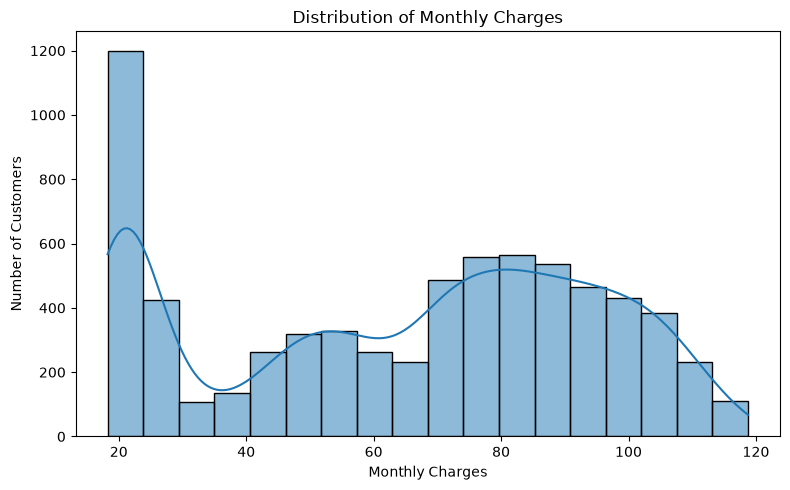

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=numerical_data,
    x="MonthlyCharges",
    kde=True
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Observation / Insight

The histogram shows how MonthlyCharges are distributed across customers.

The shape of the distribution helps identify the common charge range and whether the feature is noticeably skewed.

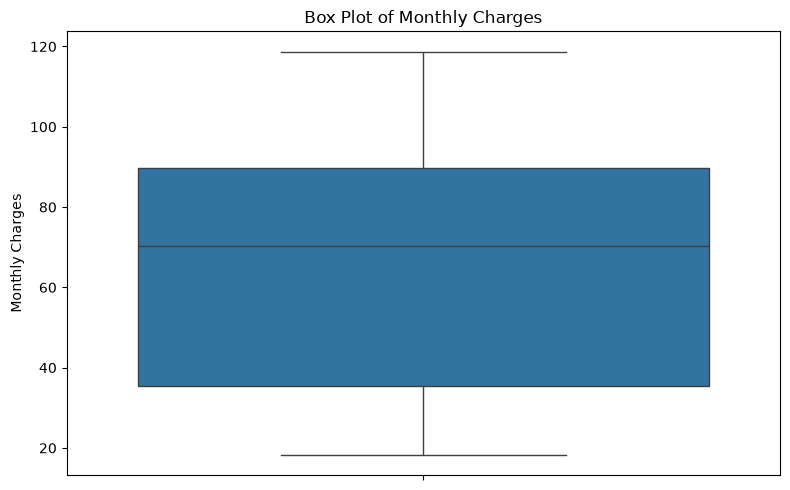

In [13]:
# Box plot code

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=numerical_data,
    y="MonthlyCharges"
)

plt.title("Box Plot of Monthly Charges")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

### Observation / Insight

The box plot shows the central range of MonthlyCharges and highlights potential extreme observations.

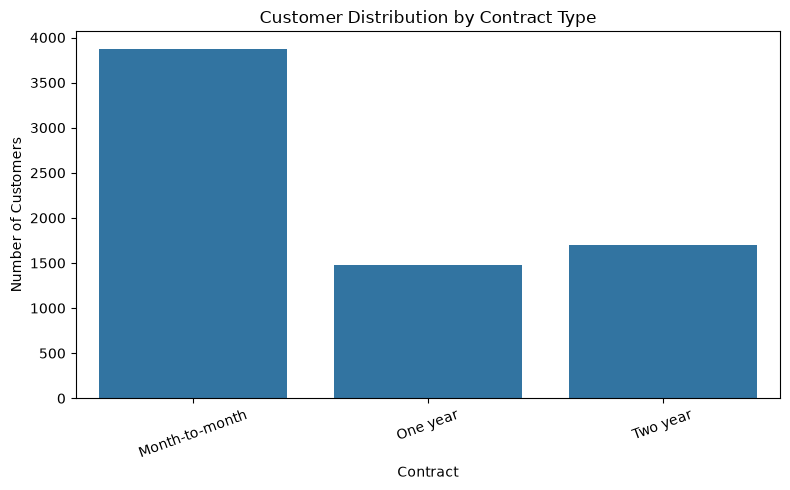

In [14]:
# count plot code

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract"
)

plt.title("Customer Distribution by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Observation / Insight

The count plot shows that customers are not equally distributed across contract types.

This helps identify which contract groups contain larger customer populations.

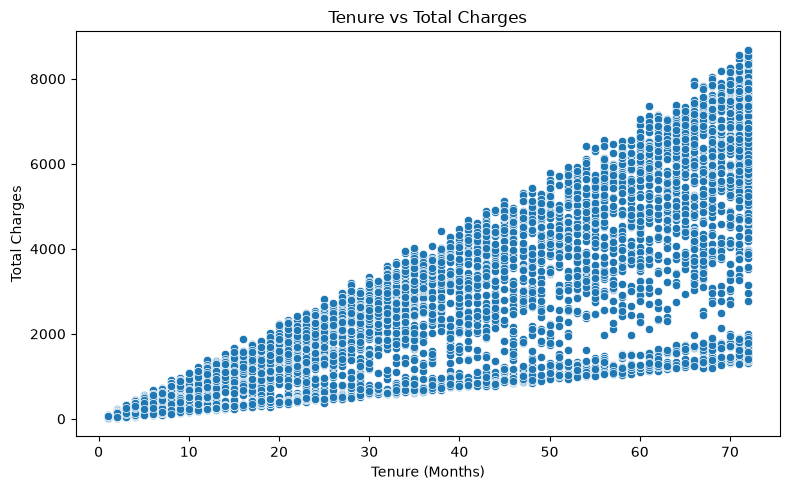

In [15]:
# scatter plot code

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=numerical_data,
    x="tenure",
    y="TotalCharges"
)

plt.title("Tenure vs Total Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")
plt.tight_layout()
plt.show()

### Observation / Insight

The scatter plot shows a strong positive relationship between tenure and TotalCharges.

As customer tenure increases, accumulated TotalCharges generally increase.

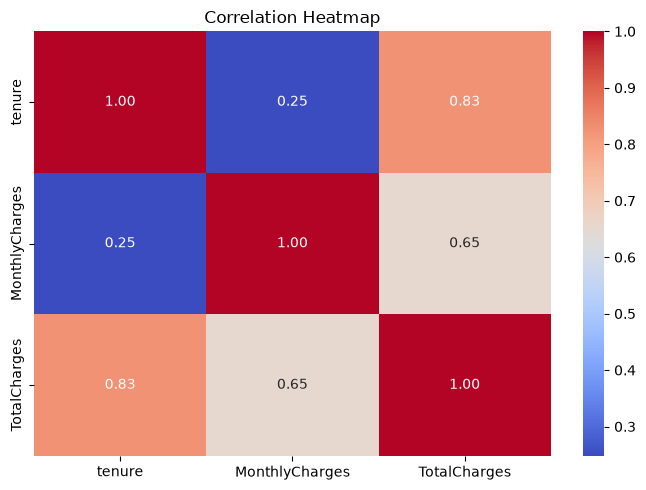

In [16]:
# Heatmap code

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Observation / Insight

The heatmap provides a visual summary of relationships between numerical features.

It makes strong and weak correlations easier to identify.

## Question 13: What important patterns can be identified?

### Step 1 – Understand the concept

Patterns are noticeable behaviors or relationships that appear repeatedly in the dataset.

### Step 2 – Demonstrate the concept

We compare churn behavior across important customer groups.

### Step 3 – Implementation the concept

We calculate churn rates by contract and internet service.

In [17]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print("Churn Rate by Contract:")
print(contract_churn)

print("\nChurn Rate by Internet Service:")
print(internet_churn)

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by Internet Service:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64


### Observation / Insight

Churn rates differ across contract types and internet service categories.

These differences indicate that customer service characteristics may be associated with churn behavior and should be investigated further.

## Question 14: What business insights can be derived from the EDA?

### Step 1 – Understand the concept

Business insights convert statistical findings and visual patterns into meaningful observations that can support business decisions.

### Step 2 – Demonstrate the concept

Instead of saying:

"The graph shows churn by contract."

We should write:

"Churn behavior differs across contract types, indicating that contract structure may be an important factor to consider when analyzing customer retention."

### Step 3 – Implementation the concept

We summarize the most important findings from the EDA.

In [18]:
overall_churn = (
    (df["Churn"] == "Yes").mean() * 100
)

average_tenure = df.groupby("Churn")["tenure"].mean()

print("===== Business Insights =====")

print("\nOverall Churn Rate:")
print(round(overall_churn, 2), "%")

print("\nAverage Tenure by Churn:")
print(average_tenure.round(2))

print("\nChurn Rate by Contract:")
print(contract_churn)

print("\nChurn Rate by Internet Service:")
print(internet_churn)

===== Business Insights =====

Overall Churn Rate:
26.54 %

Average Tenure by Churn:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by Internet Service:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64


### Business Insights

- Customer churn is not evenly distributed across the dataset.
- Contract type shows noticeable differences in churn behavior.
- Internet service categories also show differences in churn rates.
- Tenure and TotalCharges have a strong positive relationship.
- MonthlyCharges show variation across customers and contract groups.
- These patterns can help identify customer segments that require further retention analysis.

## Question 15: What should be addressed in the next preprocessing stage?

### Step 1 – Understand the concept

EDA identifies potential data problems, while preprocessing prepares the data for machine learning.

### Step 2 – Demonstrate the concept

The preprocessing stage may need to address:

- Missing values
- Incorrect data types
- Outliers
- Categorical encoding
- Feature scaling
- Skewed distributions
- Feature engineering
- Multicollinearity

### Step 3 – Implementation the concept

We document recommendations without performing complete preprocessing in this notebook.

In [19]:
recommendations = [
    "Investigate and treat missing or blank values",
    "Correct incorrect data types such as TotalCharges",
    "Investigate detected outliers",
    "Encode categorical variables",
    "Scale numerical features where required",
    "Consider transformations for highly skewed features",
    "Consider useful feature engineering",
    "Check multicollinearity before model training"
]

print("===== Preprocessing Recommendations =====")

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

===== Preprocessing Recommendations =====
1. Investigate and treat missing or blank values
2. Correct incorrect data types such as TotalCharges
3. Investigate detected outliers
4. Encode categorical variables
5. Scale numerical features where required
6. Consider transformations for highly skewed features
7. Consider useful feature engineering
8. Check multicollinearity before model training


### Observation / Insight

The EDA identified several areas that should be addressed before machine learning.

The next preprocessing stage should focus on data-type correction, missing-value treatment, categorical encoding, outlier investigation, scaling, transformation, and feature engineering where appropriate.

Complete preprocessing is intentionally not performed in this notebook.

# Final EDA Mini Challenge Summary

The dataset was independently analyzed from loading to preprocessing recommendations.

### Key Findings

- Dataset contains 7043 records and 21 columns.
- Both numerical and categorical features are present.
- `Churn` is the target variable.
- `TotalCharges` requires data-type attention.
- Missing values and duplicate records were checked.
- Numerical features were analyzed using descriptive statistics.
- Categorical features were analyzed using frequencies and distributions.
- Potential outliers were identified using the IQR method.
- Numerical distributions and skewness were analyzed.
- Correlations between numerical features were examined.
- Meaningful visualizations were created.
- Important customer behavior patterns were identified.
- Business insights were derived from the EDA findings.
- Recommendations were provided for the next preprocessing stage.

### EDA Workflow

**Load → Understand → Inspect → Analyze → Visualize → Identify Patterns → Generate Insights → Recommend**